# B7 – Phát Hiện Tấn Công Trong Hệ Thống ICS Bằng Naive Bayes
## Dữ Liệu Cảm Biến – Dataset BATADAL

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (accuracy_score, brier_score_loss,
                             classification_report, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.naive_bayes import BernoulliNB, GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (MinMaxScaler, PowerTransformer,
                                   StandardScaler)

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
# ==========================
# ĐƯỜNG DẪN DATASET
# ==========================
BASE = Path("data/BATADAL")
for _cand in [BASE, Path.cwd().parent / "B6" / "data" / "BATADAL",
              Path.cwd().parent / "B1" / "data" / "BATADAL"]:
    if (_cand / "test_dataset_1.csv").exists():
        BASE = _cand
        break

# ==========================
# NHÃN (LABELS)
# ==========================
LABEL_COL = "ATT_FLAG"              # 0 = bình thường, khác 0 = bị tấn công
TARGET_NAMES = ["Bình thường", "Tấn công"]
META_COLS = ["DATETIME"]

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42          # seed cố định để kết quả tái lập được
TEST_SIZE = 0.3    # 70% train / 30% test
CV_FOLDS = 5       # số fold của cross-validation

# ==========================
# KHÔNG GIAN SIÊU THAM SỐ
# ==========================
# var_smoothing: lượng cộng thêm vào phương sai của GaussianNB, tính theo
# tỷ lệ với phương sai lớn nhất trong các đặc trưng. Mặc định của sklearn
# là 1e-9 — bài này sẽ cho thấy giá trị mặc định đó thường quá nhỏ.
VS_GRID = [1e-11, 1e-9, 1e-7, 1e-5, 1e-3, 1e-2, 1e-1, 1.0]

# Ngưỡng tương quan để coi hai đặc trưng là "trùng lặp thông tin"
CORR_THR = 0.95

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
VARIANTS_COMMENT = (
    "\nNhận xét: GaussianNB trên dữ liệu Z-score SỤP ĐỔ (F1 ≈ 0,19) trong khi\n"
    "chính nó trên dữ liệu thô đạt ≈ 0,50. Chuẩn hóa — việc vẫn được coi là vô\n"
    "hại hoặc có lợi — lại làm hỏng mô hình. Nguyên nhân nằm ở var_smoothing và\n"
    "ở các cột trạng thái bơm/van chỉ nhận giá trị 0/1: trong một lớp chúng gần\n"
    "như hằng số, nên phương sai trong lớp xấp xỉ 0 → xem A3.\n"
    "BernoulliNB (F1 ≈ 0,65) thắng cả hai, điều dễ hiểu vì 12 trong 37 đặc\n"
    "trưng vốn đã là biến nhị phân.")
VS_COMMENT = (
    "\nNhận xét: nâng var_smoothing lên 1,0 đưa F1 từ 0,19 lên 0,63 — tăng gấp\n"
    "ba. Giá trị tối ưu ở đây lớn hơn cả hai bộ dữ liệu còn lại, đúng như dự\n"
    "đoán: dữ liệu cảm biến ICS có nhiều cột gần như hằng số trong từng lớp nên\n"
    "cần cộng thêm nhiều phương sai mới ổn định được mật độ Gauss.")
SKEW_COMMENT = (
    "\nNhận xét: chỉ 9 trong 37 đặc trưng có |độ lệch| > 2 và trung vị độ lệch\n"
    "là 1,03 — dữ liệu cảm biến ICS gần phân phối chuẩn hơn nhiều so với lưu\n"
    "lượng mạng hay PE header, vì chúng là đại lượng vật lý dao động quanh một\n"
    "điểm vận hành.\n"
    "Vì giả định ban đầu đã không bị vi phạm nặng, PowerTransformer KHÔNG giúp\n"
    "gì (0,617 so với 0,626) — ta giữ biểu diễn Z-score. Đây là trường hợp đối\n"
    "chứng hữu ích: cùng một kỹ thuật giúp rất nhiều ở hai bộ dữ liệu kia lại\n"
    "vô ích ở đây, nên không có công thức dùng chung cho mọi bài toán.")
CORR_COMMENT = (
    "\nNhận xét: 15 trong 666 cặp có |r| > 0,95, và có cặp tương quan đúng 1,0.\n"
    "Điều này tất yếu với hệ vật lý: lưu lượng qua một bơm và trạng thái bật/tắt\n"
    "của chính bơm đó mô tả cùng một hiện tượng. Giả định độc lập điều kiện của\n"
    "Naive Bayes vì vậy bị vi phạm có hệ thống chứ không phải ngẫu nhiên. Loại\n"
    "12 đặc trưng còn 25 giúp F1 nhích lên và AUC tăng rõ.")
CALIB_COMMENT = (
    "\nNhận xét: hơn 93% mẫu bị gán xác suất cực đoan — hệ quả của việc các cặp\n"
    "cảm biến tương quan khiến bằng chứng bị đếm nhiều lần. Trong vận hành SCADA,\n"
    "một mô hình luôn báo \"99% chắc chắn\" làm kỹ sư mất khả năng phân biệt\n"
    "cảnh báo nào cần xử lý trước.")
FINAL_COMMENT = (
    "\nNhận xét: ngưỡng tối ưu bị đẩy lên rất cao (0,95) vì xác suất của Naive\n"
    "Bayes quá cực đoan — phải nâng ngưỡng gần sát 1 mới cắt bớt được cảnh báo\n"
    "giả. F1 ≈ 0,63 thấp hơn hẳn KNN ở Bài 6 (≈ 0,95) và Random Forest (≈ 0,96).\n"
    "Lý do: giả định độc lập điều kiện bị vi phạm có hệ thống trên dữ liệu cảm\n"
    "biến, điều mà việc dò siêu tham số không sửa được.\n"
    "Bù lại, Naive Bayes huấn luyện nhanh hơn Random Forest tới hàng trăm lần.")
HELDOUT_COMMENT = (
    "\n" + "═" * 70 + "\n"
    "SO SÁNH VỚI BÀI 6 (KNN)\n"
    + "═" * 70 + "\n"
    "Naive Bayes trên tập held-out còn tệ hơn KNN: F1 ≈ 0,16 so với ≈ 0,36, và\n"
    "Recall chỉ ≈ 0,09 — tức bỏ sót hơn 90% số cuộc tấn công thật.\n"
    "\n"
    "Hai nguyên nhân cộng dồn:\n"
    "  (1) Rò rỉ thời gian, giống Bài 6: tập test ở A7 được tách ngẫu nhiên từ\n"
    "      cùng chuỗi thời gian nên con số trên đó đã bị thổi phồng.\n"
    "  (2) Ngưỡng 0,95 được chọn trên tập validation cũng thuộc giai đoạn thời\n"
    "      gian ấy. Sang giai đoạn tấn công khác, phân bố xác suất dịch đi và\n"
    "      ngưỡng cao đó trở nên quá chặt: mô hình gần như không báo gì nữa\n"
    "      (chỉ 10 cảnh báo giả nhưng bỏ sót 1.485 mẫu tấn công).\n"
    "\n"
    "Random Forest vẫn giữ AUC ≈ 0,87 trên held-out, cho thấy vấn đề không chỉ\n"
    "ở cách chia dữ liệu mà còn ở chính giả định của Naive Bayes.\n"
    + "═" * 70)

print("✅ Cấu hình xong!")
print(f"   Nhãn      → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   Test size → {TEST_SIZE*100:.0f}%  |  SEED = {SEED}  |  CV folds = {CV_FOLDS}")
print(f"   VS_GRID   → {VS_GRID}")
print(f"   CORR_THR  → {CORR_THR}")
print(f"   Dữ liệu   → {BASE}")


✅ Cấu hình xong!
   Nhãn      → ATT_FLAG (0 = Bình thường, 1 = Tấn công)
   Test size → 30%  |  SEED = 42  |  CV folds = 5
   VS_GRID   → [1e-11, 1e-09, 1e-07, 1e-05, 0.001, 0.01, 0.1, 1.0]
   CORR_THR  → 0.95
   Dữ liệu   → data\BATADAL


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Làm sạch DataFrame và trả về ma trận đặc trưng CHƯA biến đổi:
      1. Chỉ giữ cột số, loại cột meta và cột nhãn
      2. Thay Inf / -Inf → NaN
      3. Điền giá trị thiếu bằng median
      4. Loại cột phương sai = 0

    keep_cols: nếu truyền vào thì lấy đúng danh sách cột đó thay vì tự chọn.
    Dùng cho tập held-out — tập này buộc phải có đúng bộ đặc trưng của tập train.
    """
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# BỘ LỌC ĐẶC TRƯNG TƯƠNG QUAN CAO
# ════════════════════════════════════════════════════════════════════════════
# Naive Bayes giả định các đặc trưng ĐỘC LẬP với nhau khi đã biết nhãn. Hai
# đặc trưng tương quan gần như hoàn hảo sẽ bị mô hình đếm bằng chứng HAI LẦN,
# khiến xác suất bị đẩy về 0 hoặc 1. Bộ lọc này giữ lại một đặc trưng trong
# mỗi cặp có |tương quan| vượt ngưỡng.
#
# Viết dưới dạng transformer của scikit-learn để có thể đặt vào Pipeline —
# nhờ đó khi chạy cross-validation ở phần A8, bộ lọc được fit lại trên từng
# fold thay vì dùng kết quả tính trên toàn bộ dữ liệu (tránh rò rỉ).
class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.95):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        C = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        upper = np.triu(C, k=1)                      # chỉ xét tam giác trên
        drop = {int(j) for _, j in zip(*np.where(upper > self.threshold))}
        self.keep_ = [i for i in range(X.shape[1]) if i not in drop]
        self.n_dropped_ = X.shape[1] - len(self.keep_)
        self.n_pairs_ = int((upper > self.threshold).sum())
        self.max_corr_ = float(upper.max())
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.keep_]


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ MỘT MÔ HÌNH
# ════════════════════════════════════════════════════════════════════════════
# Ngoài các chỉ số quen thuộc, bài này thêm Brier score — trung bình bình
# phương sai lệch giữa xác suất dự đoán và nhãn thật. Brier càng NHỎ càng tốt.
# Chỉ số này cần thiết vì Naive Bayes nổi tiếng cho xác suất rất lệch.
def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
        "brier": brier_score_loss(y_true, y_score),
    }


print("✅ Đã định nghĩa clean_numeric(), CorrelationFilter(), evaluate()")


✅ Đã định nghĩa clean_numeric(), CorrelationFilter(), evaluate()


---
# Xây Dựng Mô Hình Naive Bayes

> **Bài toán:** Dự đoán hệ thống cấp nước đang **vận hành bình thường (0)** hay **bị tấn công (1)** từ các cảm biến áp suất, lưu lượng và trạng thái bơm/van.
>
> **Ý tưởng của Naive Bayes:** tính xác suất theo định lý Bayes với giả định các đặc trưng độc lập nhau khi đã biết lớp.
>
> ⚠ **Lưu ý:** dữ liệu cảm biến ICS vi phạm giả định độc lập một cách có hệ thống — lưu lượng qua một bơm và trạng thái bật/tắt của chính bơm đó mô tả cùng một hiện tượng. Hãy chú ý phần A5 và A8.

### A1. Tải & Tiền Xử Lý Dữ Liệu

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU CẢM BIẾN BATADAL")
print("═" * 70)
print("Thư mục dữ liệu:", BASE)

# train_dataset.csv chỉ chứa mẫu bình thường nên không dùng được cho Naive
# Bayes có giám sát. Giống Bài 1 và Bài 6 của CV4.4, ta dùng:
#   test_dataset_1.csv → tập có nhãn, chia 70/30 train/test
#   test_dataset_2.csv → tập held-out, giai đoạn tấn công hoàn toàn khác
test1 = pd.read_csv(BASE / "test_dataset_1.csv", index_col=0)
test2 = pd.read_csv(BASE / "test_dataset_2.csv", index_col=0)
test1.columns = test1.columns.str.strip()
test2.columns = test2.columns.str.strip()

y = (test1[LABEL_COL] != 0).astype(int).values
y_ho = (test2[LABEL_COL] != 0).astype(int).values

feature_cols = [c for c in test1.columns if c not in ("DATETIME", LABEL_COL)]
pressure = [c for c in feature_cols if c.startswith("PRESSURE")]
flow = [c for c in feature_cols if c.startswith("FLOW")]
status = [c for c in feature_cols if c.startswith("STATUS")]

print(f"\nTest 1 (tập có nhãn) : {test1.shape}")
print(f"Test 2 (held-out)    : {test2.shape}")
print(f"Số cột cảm biến      : {len(feature_cols)} "
      f"(áp suất {len(pressure)} | lưu lượng {len(flow)} | trạng thái {len(status)})")
print(f"\nTest 1 — {TARGET_NAMES[0]}={int((y == 0).sum()):,} | "
      f"{TARGET_NAMES[1]}={int((y == 1).sum()):,} ({(y == 1).mean()*100:.2f}%)")
print(f"Test 2 — {TARGET_NAMES[0]}={int((y_ho == 0).sum()):,} | "
      f"{TARGET_NAMES[1]}={int((y_ho == 1).sum()):,} ({(y_ho == 1).mean()*100:.2f}%)")

# Lưu ý cho phần A2: 12 cột STATUS_* chỉ nhận giá trị 0/1. Đây là lý do
# BernoulliNB có lợi thế tự nhiên trên bộ dữ liệu này.
X_raw, zero_var = clean_numeric(test1, LABEL_COL, META_COLS)
print(f"\n✅ Sau tiền xử lý:")
print(f"   Loại {len(zero_var)} cột phương sai = 0: {zero_var}")
print(f"   Số đặc trưng : {X_raw.shape[1]}")

# Tập held-out phải lấy ĐÚNG bộ đặc trưng của tập train
X_ho_raw, _ = clean_numeric(test2, LABEL_COL, META_COLS, keep_cols=X_raw.columns)
assert list(X_ho_raw.columns) == list(X_raw.columns), "Lệch bộ đặc trưng!"
print(f"   Held-out     : {X_ho_raw.shape[0]:,} mẫu, {X_ho_raw.shape[1]} đặc trưng")

# ── Chia train/test TRƯỚC, biến đổi SAU ─────────────────────────────────────
X_tr_raw, X_te_raw, y_tr, y_te = train_test_split(
    X_raw.values, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

scaler = StandardScaler().fit(X_tr_raw)           # cho GaussianNB
X_tr, X_te = scaler.transform(X_tr_raw), scaler.transform(X_te_raw)

minmax = MinMaxScaler().fit(X_tr_raw)             # cho Bernoulli / Multinomial
X_tr_mm = minmax.transform(X_tr_raw)
X_te_mm = np.clip(minmax.transform(X_te_raw), 0, None)

print(f"\n📦 Chia tập dữ liệu (stratified "
      f"{int((1-TEST_SIZE)*100)}/{int(TEST_SIZE*100)}):")
print(f"   Train : {X_tr.shape[0]:,} mẫu ({int(y_tr.sum()):,} tấn công)")
print(f"   Test  : {X_te.shape[0]:,} mẫu ({int(y_te.sum()):,} tấn công)")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU CẢM BIẾN BATADAL
══════════════════════════════════════════════════════════════════════
Thư mục dữ liệu: data\BATADAL



Test 1 (tập có nhãn) : (18433, 45)
Test 2 (held-out)    : (10081, 45)
Số cột cảm biến      : 43 (áp suất 19 | lưu lượng 12 | trạng thái 12)



Test 1 — Bình thường=16,465 | Tấn công=1,968 (10.68%)
Test 2 — Bình thường=8,453 | Tấn công=1,628 (16.15%)



✅ Sau tiền xử lý:
   Loại 6 cột phương sai = 0: ['FLOW_PU3', 'FLOW_PU5', 'FLOW_PU9', 'STATUS_PU3', 'STATUS_PU5', 'STATUS_PU9']
   Số đặc trưng : 37
   Held-out     : 10,081 mẫu, 37 đặc trưng

📦 Chia tập dữ liệu (stratified 70/30):
   Train : 12,903 mẫu (1,378 tấn công)
   Test  : 5,530 mẫu (590 tấn công)


### A2. Ba Biến Thể Naive Bayes: Gaussian, Bernoulli, Multinomial

                                       acc    prec     rec      f1     auc  \
model                                                                        
GaussianNB (dữ liệu thô)            0.8486  0.3855  0.7051  0.4985  0.8744   
GaussianNB (Z-score)                0.1101  0.1071  1.0000  0.1934  0.8742   
BernoulliNB (MinMax, binarize=0.5)  0.9363  0.7960  0.5424  0.6452  0.8635   
MultinomialNB (MinMax)              0.9335  0.8854  0.4322  0.5809  0.8625   

                                     brier  
model                                       
GaussianNB (dữ liệu thô)            0.1301  
GaussianNB (Z-score)                0.8899  
BernoulliNB (MinMax, binarize=0.5)  0.0608  
MultinomialNB (MinMax)              0.0615  

GaussianNB: thô F1 = 0.4985 | Z-score F1 = 0.1934  → chênh -0.3051

Nhận xét: GaussianNB trên dữ liệu Z-score SỤP ĐỔ (F1 ≈ 0,19) trong khi
chính nó trên dữ liệu thô đạt ≈ 0,50. Chuẩn hóa — việc vẫn được coi là vô
hại hoặc có lợi — lại làm hỏng mô hình. Nguyên 

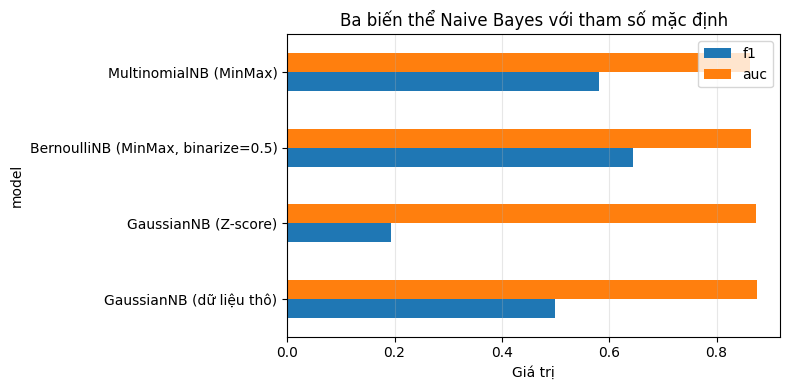

In [5]:
# Naive Bayes dựa trên định lý Bayes cùng một giả định đơn giản hóa mạnh:
# các đặc trưng ĐỘC LẬP với nhau khi đã biết nhãn. Nhờ đó xác suất hợp của
# nhiều đặc trưng trở thành phép nhân các xác suất lẻ, và mô hình chỉ cần
# đếm thống kê từng đặc trưng một lần — huấn luyện cực nhanh.
#
# Ba biến thể khác nhau ở chỗ mô hình hóa P(đặc trưng | lớp) như thế nào:
#   GaussianNB    – giả định mỗi đặc trưng theo phân phối chuẩn trong từng lớp
#   BernoulliNB   – giả định đặc trưng nhị phân (có / không), cần binarize
#   MultinomialNB – giả định đặc trưng là số đếm không âm, cần đưa về [0, 1]
rows = []

g_raw = GaussianNB().fit(X_tr_raw, y_tr)
rows.append(evaluate(y_te, g_raw.predict(X_te_raw),
                     g_raw.predict_proba(X_te_raw)[:, 1], "GaussianNB (dữ liệu thô)"))

g_std = GaussianNB().fit(X_tr, y_tr)
rows.append(evaluate(y_te, g_std.predict(X_te),
                     g_std.predict_proba(X_te)[:, 1], "GaussianNB (Z-score)"))

bnb = BernoulliNB(binarize=0.5).fit(X_tr_mm, y_tr)
rows.append(evaluate(y_te, bnb.predict(X_te_mm),
                     bnb.predict_proba(X_te_mm)[:, 1], "BernoulliNB (MinMax, binarize=0.5)"))

mnb = MultinomialNB().fit(X_tr_mm, y_tr)
rows.append(evaluate(y_te, mnb.predict(X_te_mm),
                     mnb.predict_proba(X_te_mm)[:, 1], "MultinomialNB (MinMax)"))

var_df = pd.DataFrame(rows).set_index("model").round(4)
print(var_df[["acc", "prec", "rec", "f1", "auc", "brier"]])
print(f"\nGaussianNB: thô F1 = {rows[0]['f1']:.4f} | Z-score F1 = {rows[1]['f1']:.4f}"
      f"  → chênh {rows[1]['f1'] - rows[0]['f1']:+.4f}")
print(VARIANTS_COMMENT)

ax = var_df[["f1", "auc"]].plot.barh(figsize=(8, 4))
ax.set_xlabel("Giá trị")
ax.set_title("Ba biến thể Naive Bayes với tham số mặc định")
ax.grid(axis="x", alpha=.3)
plt.tight_layout()
plt.show()


### A3. var_smoothing – Siêu Tham Số Quyết Định Của GaussianNB

                  acc    prec     rec      f1     auc
var_smoothing                                        
1.000000e-11   0.1101  0.1071  1.0000  0.1934  0.8676
1.000000e-09   0.1101  0.1071  1.0000  0.1934  0.8742
1.000000e-07   0.1101  0.1071  1.0000  0.1934  0.8743
1.000000e-05   0.2467  0.1236  0.9949  0.2199  0.8743
1.000000e-03   0.8369  0.3673  0.7322  0.4892  0.8743
1.000000e-02   0.8917  0.4939  0.6153  0.5479  0.8744
1.000000e-01   0.9221  0.6667  0.5390  0.5961  0.8750
1.000000e+00   0.9383  0.8879  0.4831  0.6257  0.8786

→ var_smoothing tốt nhất trên dữ liệu Z-score: 1  (F1 = 0.6257)
→ So với mặc định 1e-09 (F1 = 0.1934): +0.4323

Nhận xét: nâng var_smoothing lên 1,0 đưa F1 từ 0,19 lên 0,63 — tăng gấp
ba. Giá trị tối ưu ở đây lớn hơn cả hai bộ dữ liệu còn lại, đúng như dự
đoán: dữ liệu cảm biến ICS có nhiều cột gần như hằng số trong từng lớp nên
cần cộng thêm nhiều phương sai mới ổn định được mật độ Gauss.


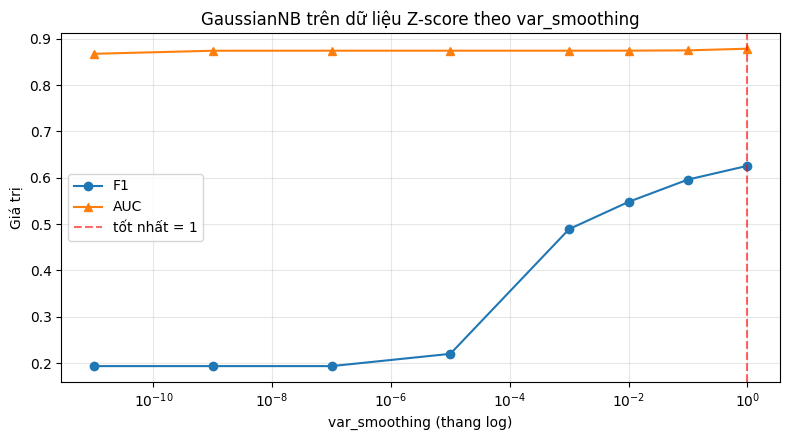

In [6]:
# Về lý thuyết, GaussianNB BẤT BIẾN với phép co giãn tuyến tính từng đặc
# trưng: nó chỉ ước lượng trung bình và phương sai của mỗi đặc trưng trong
# mỗi lớp. Nhưng kết quả ở A2 cho thấy chuẩn hóa lại làm thay đổi F1 rất
# mạnh. Nguyên nhân nằm ở var_smoothing.
#
# scikit-learn cộng thêm vào phương sai mỗi đặc trưng một lượng
#     var_smoothing × (phương sai LỚN NHẤT trong toàn bộ các đặc trưng)
# Trên dữ liệu thô, phương sai lớn nhất có thể tới hàng tỷ nên lượng cộng
# thêm rất đáng kể. Sau khi chuẩn hóa, mọi phương sai bằng 1 nên lượng cộng
# thêm chỉ còn 1e-9 — gần như bằng 0. Khi đó đặc trưng nào có phương sai
# trong lớp xấp xỉ 0 sẽ tạo ra mật độ Gauss cực nhọn, đẩy xác suất về 0 hoặc
# 1 và làm mô hình sụp đổ.
rows = []
for v in VS_GRID:
    g = GaussianNB(var_smoothing=v).fit(X_tr, y_tr)
    rows.append(evaluate(y_te, g.predict(X_te), g.predict_proba(X_te)[:, 1], v))

vs_df = pd.DataFrame(rows).set_index("model").round(4)
vs_df.index.name = "var_smoothing"
print(vs_df[["acc", "prec", "rec", "f1", "auc"]])

vs_best = vs_df["f1"].idxmax()
print(f"\n→ var_smoothing tốt nhất trên dữ liệu Z-score: {vs_best:g}"
      f"  (F1 = {vs_df.loc[vs_best, 'f1']:.4f})")
print(f"→ So với mặc định 1e-09 (F1 = {vs_df.loc[1e-9, 'f1']:.4f}): "
      f"{vs_df.loc[vs_best, 'f1'] - vs_df.loc[1e-9, 'f1']:+.4f}")
print(VS_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogx(vs_df.index, vs_df["f1"], marker="o", label="F1")
ax.semilogx(vs_df.index, vs_df["auc"], marker="^", label="AUC")
ax.axvline(vs_best, color="red", ls="--", alpha=.6,
           label=f"tốt nhất = {vs_best:g}")
ax.set_xlabel("var_smoothing (thang log)")
ax.set_ylabel("Giá trị")
ax.set_title("GaussianNB trên dữ liệu Z-score theo var_smoothing")
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A4. Kiểm Tra Giả Định Phân Phối Chuẩn

Độ lệch tuyệt đối của 37 đặc trưng (dữ liệu Z-score):
   trung vị      : 1.03
   lớn nhất      : 46.3
   số đặc trưng có |độ lệch| > 2  : 9
   số đặc trưng có |độ lệch| > 10 : 5



Sau PowerTransformer:
   trung vị      : 0.29
   số đặc trưng có |độ lệch| > 2  : 7

GaussianNB trên dữ liệu PowerTransformer:
                   f1     auc   brier
var_smoothing                        
1.000000e-11   0.1934  0.8701  0.8899
1.000000e-09   0.1934  0.8737  0.8899
1.000000e-07   0.1934  0.8736  0.8896
1.000000e-05   0.2021  0.8736  0.7481
1.000000e-03   0.4358  0.8736  0.1680
1.000000e-02   0.5362  0.8736  0.0927
1.000000e-01   0.6170  0.8741  0.0637
1.000000e+00   0.6109  0.8767  0.0612

→ Z-score            : F1 = 0.6257 (var_smoothing = 1)
→ PowerTransformer   : F1 = 0.6170 (var_smoothing = 0.1)
→ Biểu diễn dùng cho các phần sau: Z-score với var_smoothing = 1

Nhận xét: chỉ 9 trong 37 đặc trưng có |độ lệch| > 2 và trung vị độ lệch
là 1,03 — dữ liệu cảm biến ICS gần phân phối chuẩn hơn nhiều so với lưu
lượng mạng hay PE header, vì chúng là đại lượng vật lý dao động quanh một
điểm vận hành.
Vì giả định ban đầu đã không bị vi phạm nặng, PowerTransformer KHÔNG giúp
gì (0,

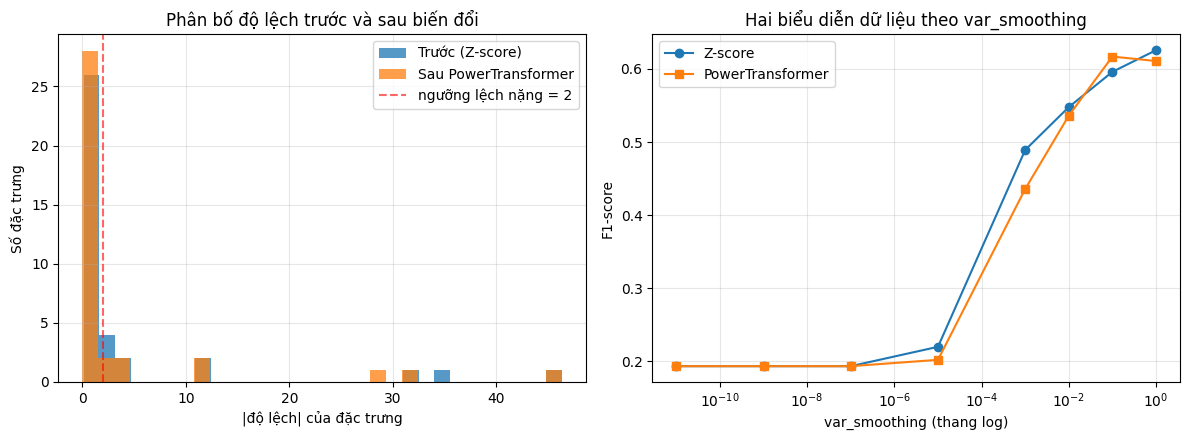

In [7]:
# GaussianNB giả định mỗi đặc trưng theo phân phối CHUẨN trong từng lớp.
# Ta kiểm tra giả định đó bằng độ lệch (skewness): phân phối chuẩn có độ
# lệch 0, |độ lệch| > 2 là lệch nặng.
#
# Độ lệch bất biến với phép co giãn tuyến tính, nên tính trên dữ liệu đã
# chuẩn hóa cho kết quả giống hệt dữ liệu thô nhưng không bị tràn số học.
skew_before = pd.DataFrame(X_tr).skew().abs()
print(f"Độ lệch tuyệt đối của {X_tr.shape[1]} đặc trưng (dữ liệu Z-score):")
print(f"   trung vị      : {skew_before.median():.2f}")
print(f"   lớn nhất      : {skew_before.max():.1f}")
print(f"   số đặc trưng có |độ lệch| > 2  : {int((skew_before > 2).sum())}")
print(f"   số đặc trưng có |độ lệch| > 10 : {int((skew_before > 10).sum())}")

# PowerTransformer (Yeo-Johnson) tìm một phép biến đổi lũy thừa cho từng đặc
# trưng sao cho kết quả gần phân phối chuẩn nhất, rồi chuẩn hóa về N(0, 1).
# Khác với log, Yeo-Johnson xử lý được cả giá trị âm và giá trị 0.
pt = PowerTransformer(method="yeo-johnson", standardize=True).fit(X_tr_raw)
X_tr_pt, X_te_pt = pt.transform(X_tr_raw), pt.transform(X_te_raw)

skew_after = pd.DataFrame(X_tr_pt).skew().abs()
print(f"\nSau PowerTransformer:")
print(f"   trung vị      : {skew_after.median():.2f}")
print(f"   số đặc trưng có |độ lệch| > 2  : {int((skew_after > 2).sum())}")

rows = []
for v in VS_GRID:
    g = GaussianNB(var_smoothing=v).fit(X_tr_pt, y_tr)
    rows.append(evaluate(y_te, g.predict(X_te_pt),
                         g.predict_proba(X_te_pt)[:, 1], v))
pt_df = pd.DataFrame(rows).set_index("model").round(4)
pt_df.index.name = "var_smoothing"
print(f"\nGaussianNB trên dữ liệu PowerTransformer:")
print(pt_df[["f1", "auc", "brier"]])

vs_best_pt = pt_df["f1"].idxmax()
f1_std, f1_pt = vs_df.loc[vs_best, "f1"], pt_df.loc[vs_best_pt, "f1"]
print(f"\n→ Z-score            : F1 = {f1_std:.4f} (var_smoothing = {vs_best:g})")
print(f"→ PowerTransformer   : F1 = {f1_pt:.4f} (var_smoothing = {vs_best_pt:g})")

# Chọn biểu diễn tốt hơn làm biểu diễn cuối cho các phần sau
if f1_pt >= f1_std:
    REPR, X_tr_f, X_te_f, VS_F, tf_final = "PowerTransformer", X_tr_pt, X_te_pt, vs_best_pt, pt
else:
    REPR, X_tr_f, X_te_f, VS_F, tf_final = "Z-score", X_tr, X_te, vs_best, scaler
print(f"→ Biểu diễn dùng cho các phần sau: {REPR} "
      f"với var_smoothing = {VS_F:g}")
print(SKEW_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(skew_before, bins=30, alpha=.75, label="Trước (Z-score)")
axes[0].hist(skew_after, bins=30, alpha=.75, label="Sau PowerTransformer")
axes[0].axvline(2, color="red", ls="--", alpha=.6, label="ngưỡng lệch nặng = 2")
axes[0].set_xlabel("|độ lệch| của đặc trưng")
axes[0].set_ylabel("Số đặc trưng")
axes[0].set_title("Phân bố độ lệch trước và sau biến đổi")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].semilogx(vs_df.index, vs_df["f1"], marker="o", label="Z-score")
axes[1].semilogx(pt_df.index, pt_df["f1"], marker="s", label="PowerTransformer")
axes[1].set_xlabel("var_smoothing (thang log)")
axes[1].set_ylabel("F1-score")
axes[1].set_title("Hai biểu diễn dữ liệu theo var_smoothing")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A5. Kiểm Tra Giả Định Độc Lập Điều Kiện

Số cặp đặc trưng : 666
Số cặp có |r| > 0.95 : 15
Tương quan lớn nhất giữa hai đặc trưng khác nhau: 1.0000

Loại 12 đặc trưng, còn lại 25

                                      acc    prec     rec      f1     auc  \
model                                                                       
Toàn bộ 37 đặc trưng               0.9383  0.8879  0.4831  0.6257  0.8786   
Sau lọc tương quan (25 đặc trưng)  0.9389  0.8938  0.4847  0.6286  0.8972   

                                    brier  
model                                      
Toàn bộ 37 đặc trưng               0.0601  
Sau lọc tương quan (25 đặc trưng)  0.0551  

Nhận xét: 15 trong 666 cặp có |r| > 0,95, và có cặp tương quan đúng 1,0.
Điều này tất yếu với hệ vật lý: lưu lượng qua một bơm và trạng thái bật/tắt
của chính bơm đó mô tả cùng một hiện tượng. Giả định độc lập điều kiện của
Naive Bayes vì vậy bị vi phạm có hệ thống chứ không phải ngẫu nhiên. Loại
12 đặc trưng còn 25 giúp F1 nhích lên và AUC tăng rõ.


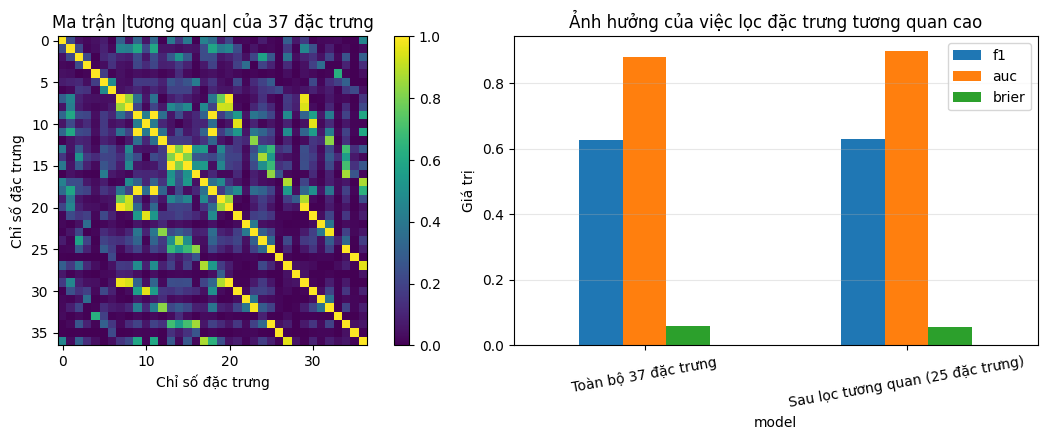

In [8]:
# Giả định "độc lập điều kiện" là chỗ chữ NAIVE trong tên thuật toán. Dữ
# liệu thật hầu như luôn vi phạm nó. Ta đo mức vi phạm bằng cách đếm số cặp
# đặc trưng có |tương quan| vượt ngưỡng, rồi thử loại bớt và đo lại.
cf = CorrelationFilter(threshold=CORR_THR).fit(X_tr_f)
n_pairs_total = X_tr_f.shape[1] * (X_tr_f.shape[1] - 1) // 2

print(f"Số cặp đặc trưng : {n_pairs_total:,}")
print(f"Số cặp có |r| > {CORR_THR} : {cf.n_pairs_}")
print(f"Tương quan lớn nhất giữa hai đặc trưng khác nhau: {cf.max_corr_:.4f}")
print(f"\nLoại {cf.n_dropped_} đặc trưng, còn lại {len(cf.keep_)}")

X_tr_cf, X_te_cf = cf.transform(X_tr_f), cf.transform(X_te_f)
g_full = GaussianNB(var_smoothing=VS_F).fit(X_tr_f, y_tr)
g_cf = GaussianNB(var_smoothing=VS_F).fit(X_tr_cf, y_tr)

rows = [
    evaluate(y_te, g_full.predict(X_te_f), g_full.predict_proba(X_te_f)[:, 1],
             f"Toàn bộ {X_tr_f.shape[1]} đặc trưng"),
    evaluate(y_te, g_cf.predict(X_te_cf), g_cf.predict_proba(X_te_cf)[:, 1],
             f"Sau lọc tương quan ({len(cf.keep_)} đặc trưng)"),
]
corr_df = pd.DataFrame(rows).set_index("model").round(4)
print()
print(corr_df[["acc", "prec", "rec", "f1", "auc", "brier"]])
print(CORR_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
C = np.nan_to_num(np.abs(np.corrcoef(np.asarray(X_tr_f, dtype=float), rowvar=False)))
im = axes[0].imshow(C, cmap="viridis", vmin=0, vmax=1)
axes[0].set_title(f"Ma trận |tương quan| của {X_tr_f.shape[1]} đặc trưng")
axes[0].set_xlabel("Chỉ số đặc trưng")
axes[0].set_ylabel("Chỉ số đặc trưng")
plt.colorbar(im, ax=axes[0], fraction=.046)

corr_df[["f1", "auc", "brier"]].plot.bar(ax=axes[1], rot=10)
axes[1].set_title("Ảnh hưởng của việc lọc đặc trưng tương quan cao")
axes[1].set_ylabel("Giá trị")
axes[1].grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A6. Hiệu Chỉnh Xác Suất (Calibration) & Điểm Brier

Tỷ lệ mẫu test được gán xác suất < 1% hoặc > 99%: 93.13%
Brier score khi chưa hiệu chỉnh : 0.0601
Brier score sau hiệu chỉnh      : 0.0517

                         acc    prec     rec      f1     auc   brier
model                                                               
Chưa hiệu chỉnh       0.9383  0.8879  0.4831  0.6257  0.8786  0.0601
Isotonic calibration  0.9412  0.9682  0.4644  0.6277  0.8793  0.0517

Nhận xét: hơn 93% mẫu bị gán xác suất cực đoan — hệ quả của việc các cặp
cảm biến tương quan khiến bằng chứng bị đếm nhiều lần. Trong vận hành SCADA,
một mô hình luôn báo "99% chắc chắn" làm kỹ sư mất khả năng phân biệt
cảnh báo nào cần xử lý trước.


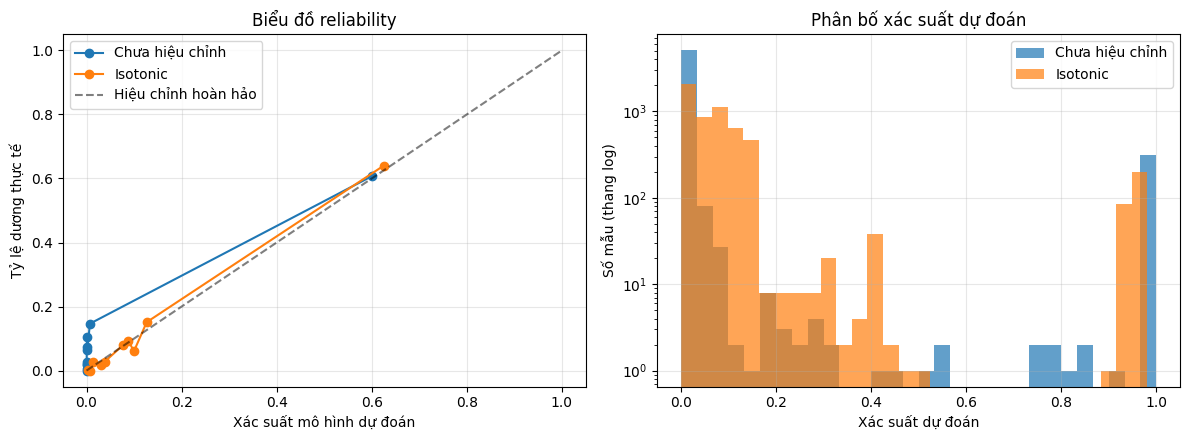

In [9]:
# Naive Bayes cho thứ hạng khá tốt (AUC cao) nhưng xác suất rất lệch: vì nhân
# dồn nhiều xác suất lẻ của các đặc trưng không thực sự độc lập, kết quả bị
# đẩy sát 0 hoặc 1. Mô hình "nói" 99% trong khi thực tế chỉ đúng 70%.
#
# Brier score đo trực tiếp sai lệch đó. Biểu đồ reliability vẽ tỷ lệ dương
# thực tế theo từng khoảng xác suất dự đoán — đường lý tưởng là đường chéo.
base = GaussianNB(var_smoothing=VS_F).fit(X_tr_f, y_tr)
p_uncal = base.predict_proba(X_te_f)[:, 1]

frac_extreme = ((p_uncal < 0.01) | (p_uncal > 0.99)).mean()
print(f"Tỷ lệ mẫu test được gán xác suất < 1% hoặc > 99%: {frac_extreme:.2%}")
print(f"Brier score khi chưa hiệu chỉnh : {brier_score_loss(y_te, p_uncal):.4f}")

# CalibratedClassifierCV học lại một hàm đơn điệu ánh xạ điểm của mô hình
# sang xác suất thật, dùng cross-validation nội bộ trên tập train.
cal = CalibratedClassifierCV(GaussianNB(var_smoothing=VS_F),
                             method="isotonic", cv=5)
cal.fit(X_tr_f, y_tr)
p_cal = cal.predict_proba(X_te_f)[:, 1]
print(f"Brier score sau hiệu chỉnh      : {brier_score_loss(y_te, p_cal):.4f}")

rows = [
    evaluate(y_te, base.predict(X_te_f), p_uncal, "Chưa hiệu chỉnh"),
    evaluate(y_te, cal.predict(X_te_f), p_cal, "Isotonic calibration"),
]
cal_df = pd.DataFrame(rows).set_index("model").round(4)
print()
print(cal_df[["acc", "prec", "rec", "f1", "auc", "brier"]])
print(CALIB_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for nm, p in [("Chưa hiệu chỉnh", p_uncal), ("Isotonic", p_cal)]:
    ft, mp = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[0].plot(mp, ft, marker="o", label=nm)
axes[0].plot([0, 1], [0, 1], "k--", alpha=.5, label="Hiệu chỉnh hoàn hảo")
axes[0].set_xlabel("Xác suất mô hình dự đoán")
axes[0].set_ylabel("Tỷ lệ dương thực tế")
axes[0].set_title("Biểu đồ reliability")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].hist(p_uncal, bins=30, alpha=.7, label="Chưa hiệu chỉnh")
axes[1].hist(p_cal, bins=30, alpha=.7, label="Isotonic")
axes[1].set_yscale("log")
axes[1].set_xlabel("Xác suất dự đoán")
axes[1].set_ylabel("Số mẫu (thang log)")
axes[1].set_title("Phân bố xác suất dự đoán")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A7. Chọn Tập Đặc Trưng, Ngưỡng Quyết Định & Mô Hình Cuối

Tách từ tập train: 10,322 mẫu để fit | 2,581 mẫu validation

F1 trên tập validation:
   Toàn bộ đặc trưng     : 0.5742
   Lọc tương quan        : 0.5769
→ Dùng bộ lọc tương quan: True
→ Số đặc trưng của mô hình cuối: 25

→ Ngưỡng tốt nhất trên validation: 0.95 (F1 = 0.5955; tại ngưỡng 0.50 chỉ đạt 0.5769)



                                      acc    prec     rec      f1  f1_macro  \
model                                                                         
GaussianNB (ngưỡng mặc định 0.50)  0.9389  0.8938  0.4847  0.6286    0.7976   
GaussianNB (Z-score, ngưỡng 0.95)  0.9418  0.9718  0.4678  0.6316    0.8000   
Random Forest (200 cây)            0.9913  0.9945  0.9237  0.9578    0.9765   

                                      auc   brier  
model                                              
GaussianNB (ngưỡng mặc định 0.50)  0.8972  0.0551  
GaussianNB (Z-score, ngưỡng 0.95)  0.8972  0.0551  
Random Forest (200 cây)            0.9968  0.0068  

Thời gian huấn luyện: Naive Bayes 7.6 ms | Random Forest 2580.0 ms  → nhanh hơn khoảng 340 lần

Confusion matrix Naive Bayes:  TN=4932  FP=8  FN=314  TP=276
  FP = 8 cảnh báo giả | FN = 314 lần bỏ sót tấn công

              precision    recall  f1-score   support

 Bình thường     0.9401    0.9984    0.9684      4940
    Tấn công     0.971

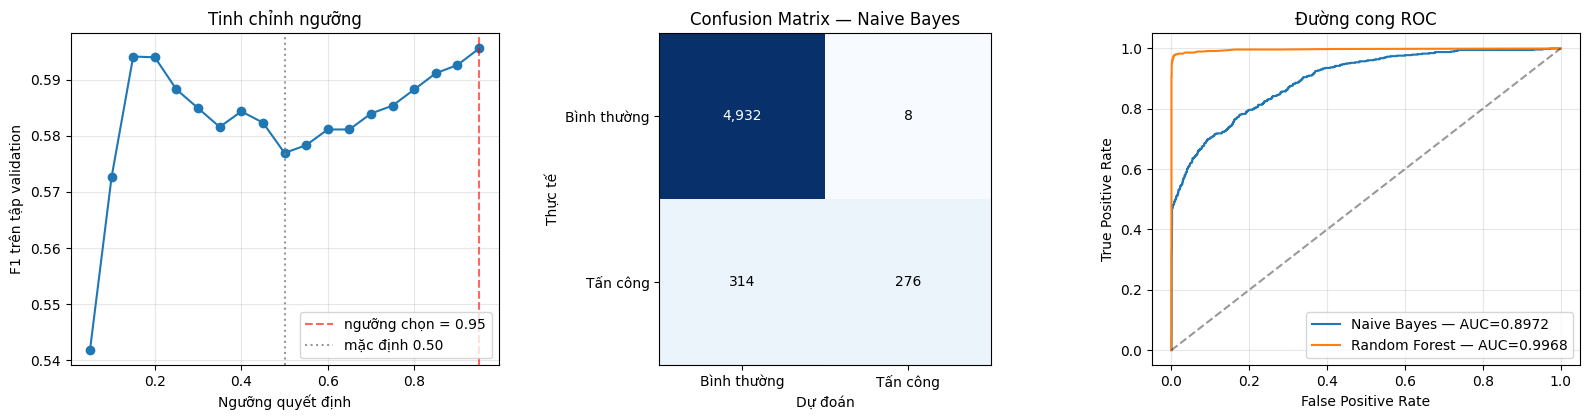

In [10]:
# Hai quyết định còn lại — dùng bộ lọc tương quan hay không, và chọn ngưỡng
# quyết định nào — phải được đưa ra trên dữ liệu MÔ HÌNH CHƯA THẤY, nhưng
# cũng KHÔNG ĐƯỢC dùng tập test. Nếu chọn theo điểm trên tập test thì tập
# test không còn là phép thử độc lập nữa.
# Vì vậy ta tách thêm một tập validation từ chính tập train.
X_a, X_v, y_a, y_v = train_test_split(X_tr_f, y_tr, test_size=0.2,
                                      random_state=SEED, stratify=y_tr)
print(f"Tách từ tập train: {X_a.shape[0]:,} mẫu để fit | "
      f"{X_v.shape[0]:,} mẫu validation")

# ── Quyết định 1: có dùng bộ lọc tương quan hay không ───────────────────────
pick = {}
for tag, use in [("Toàn bộ đặc trưng", False), ("Lọc tương quan", True)]:
    if use:
        c = CorrelationFilter(threshold=CORR_THR).fit(X_a)
        A, V = c.transform(X_a), c.transform(X_v)
    else:
        A, V = X_a, X_v
    g = GaussianNB(var_smoothing=VS_F).fit(A, y_a)
    pick[tag] = f1_score(y_v, g.predict(V), zero_division=0)

print("\nF1 trên tập validation:")
for k, v in pick.items():
    print(f"   {k:22s}: {v:.4f}")
USE_CF = pick["Lọc tương quan"] > pick["Toàn bộ đặc trưng"]
print(f"→ Dùng bộ lọc tương quan: {USE_CF}")

if USE_CF:
    c_val = CorrelationFilter(threshold=CORR_THR).fit(X_a)
    A, V = c_val.transform(X_a), c_val.transform(X_v)
    cf_final = CorrelationFilter(threshold=CORR_THR).fit(X_tr_f)
    X_tr_sel, X_te_sel = cf_final.transform(X_tr_f), cf_final.transform(X_te_f)
else:
    A, V = X_a, X_v
    cf_final = None
    X_tr_sel, X_te_sel = X_tr_f, X_te_f
print(f"→ Số đặc trưng của mô hình cuối: {X_tr_sel.shape[1]}")

# ── Quyết định 2: ngưỡng quyết định ─────────────────────────────────────────
# Ngưỡng mặc định 0.5 chỉ hợp lý khi xác suất đã được hiệu chỉnh tốt và hai
# lớp cân bằng. Với Naive Bayes thì cả hai điều đó đều không đúng.
g_val = GaussianNB(var_smoothing=VS_F).fit(A, y_a)
p_val = g_val.predict_proba(V)[:, 1]
THR_GRID = np.arange(0.05, 0.96, 0.05)
f1_by_thr = [f1_score(y_v, (p_val >= t).astype(int), zero_division=0)
             for t in THR_GRID]
THR = float(THR_GRID[int(np.argmax(f1_by_thr))])
print(f"\n→ Ngưỡng tốt nhất trên validation: {THR:.2f} "
      f"(F1 = {max(f1_by_thr):.4f}; tại ngưỡng 0.50 chỉ đạt "
      f"{f1_score(y_v, (p_val >= 0.5).astype(int), zero_division=0):.4f})")

# ── Mô hình cuối, huấn luyện lại trên toàn bộ tập train ────────────────────
final = GaussianNB(var_smoothing=VS_F).fit(X_tr_sel, y_tr)
p_final = final.predict_proba(X_te_sel)[:, 1]
y_pred = (p_final >= THR).astype(int)

nb_res = evaluate(y_te, y_pred, p_final,
                  f"GaussianNB ({REPR}, ngưỡng {THR:.2f})")
nb_res_05 = evaluate(y_te, (p_final >= 0.5).astype(int), p_final,
                     "GaussianNB (ngưỡng mặc định 0.50)")

# ── So sánh với Random Forest, kèm thời gian huấn luyện ────────────────────
t0 = time.perf_counter()
GaussianNB(var_smoothing=VS_F).fit(X_tr_sel, y_tr)
t_nb = time.perf_counter() - t0

rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
t0 = time.perf_counter()
rf.fit(X_tr_sel, y_tr)
t_rf = time.perf_counter() - t0
rf_score = rf.predict_proba(X_te_sel)[:, 1]
rf_res = evaluate(y_te, rf.predict(X_te_sel), rf_score, "Random Forest (200 cây)")

cmp_df = pd.DataFrame([nb_res_05, nb_res, rf_res]).set_index("model").round(4)
print()
print(cmp_df[["acc", "prec", "rec", "f1", "f1_macro", "auc", "brier"]])
print(f"\nThời gian huấn luyện: Naive Bayes {t_nb*1000:.1f} ms | "
      f"Random Forest {t_rf*1000:.1f} ms  → nhanh hơn khoảng "
      f"{t_rf/max(t_nb, 1e-9):.0f} lần")

cm = confusion_matrix(y_te, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion matrix Naive Bayes:  TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"  FP = {fp} cảnh báo giả | FN = {fn} lần bỏ sót {TARGET_NAMES[1].lower()}")
print("\n" + classification_report(y_te, y_pred, target_names=TARGET_NAMES,
                                    digits=4))
print(FINAL_COMMENT)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].plot(THR_GRID, f1_by_thr, marker="o")
axes[0].axvline(THR, color="red", ls="--", alpha=.6, label=f"ngưỡng chọn = {THR:.2f}")
axes[0].axvline(0.5, color="gray", ls=":", alpha=.8, label="mặc định 0.50")
axes[0].set_xlabel("Ngưỡng quyết định")
axes[0].set_ylabel("F1 trên tập validation")
axes[0].set_title("Tinh chỉnh ngưỡng")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm.max() / 2 else "black")
axes[1].set_xticks([0, 1], TARGET_NAMES)
axes[1].set_yticks([0, 1], TARGET_NAMES)
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")
axes[1].set_title("Confusion Matrix — Naive Bayes")

for nm, sc in [("Naive Bayes", p_final), ("Random Forest", rf_score)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[2].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[2].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("Đường cong ROC")
axes[2].legend()
axes[2].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A8. Đánh Giá Trên Tập Held-Out (test_dataset_2)

Tập held-out sau biến đổi: (10081, 25)

                                      acc    prec     rec      f1  f1_macro  \
model                                                                         
GaussianNB (Z-score, ngưỡng 0.95)  0.9418  0.9718  0.4678  0.6316    0.8000   
Naive Bayes — Test 2 (held-out)    0.8517  0.9346  0.0878  0.1606    0.5396   
Random Forest (200 cây)            0.9913  0.9945  0.9237  0.9578    0.9765   
Random Forest — Test 2 (held-out)  0.8848  0.9834  0.2918  0.4500    0.6929   

                                      auc  
model                                      
GaussianNB (Z-score, ngưỡng 0.95)  0.8972  
Naive Bayes — Test 2 (held-out)    0.6512  
Random Forest (200 cây)            0.9968  
Random Forest — Test 2 (held-out)  0.8695  

Confusion matrix trên Test 2:  TN=8443  FP=10  FN=1485  TP=143

→ F1 tụt từ 0.6316 (test ngẫu nhiên) xuống 0.1606 (held-out thật)
→ Recall chỉ còn 0.0878: bỏ sót 1,485/1,628 mẫu tấn công
→ Random Forest trên cùng tập đó:

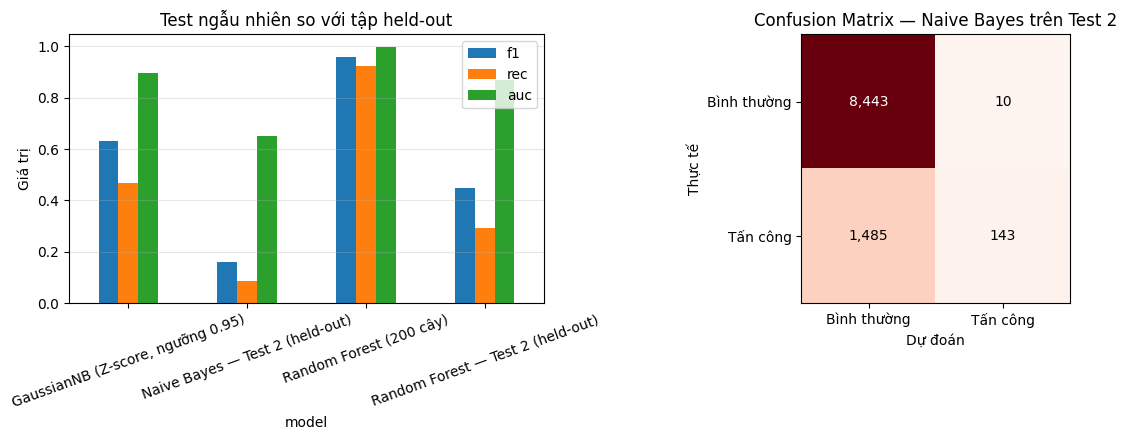

In [11]:
# Giống Bài 6 (KNN), tập test ở A7 được tách NGẪU NHIÊN từ cùng chuỗi thời
# gian với tập train, nên kết quả trên đó bị rò rỉ thời gian. test_dataset_2
# thuộc một giai đoạn tấn công hoàn toàn khác — đây mới là phép thử thật.
X_ho = tf_final.transform(X_ho_raw.values)
if cf_final is not None:
    X_ho = cf_final.transform(X_ho)
print(f"Tập held-out sau biến đổi: {X_ho.shape}")

p_ho = final.predict_proba(X_ho)[:, 1]
yp_ho = (p_ho >= THR).astype(int)
ho_res = evaluate(y_ho, yp_ho, p_ho, "Naive Bayes — Test 2 (held-out)")

rf_ho_score = rf.predict_proba(X_ho)[:, 1]
rf_ho = evaluate(y_ho, rf.predict(X_ho), rf_ho_score,
                 "Random Forest — Test 2 (held-out)")

ho_df = pd.DataFrame([nb_res, ho_res, rf_res, rf_ho]).set_index("model").round(4)
print()
print(ho_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])

cm_ho = confusion_matrix(y_ho, yp_ho)
tn2, fp2, fn2, tp2 = cm_ho.ravel()
print(f"\nConfusion matrix trên Test 2:  TN={tn2}  FP={fp2}  FN={fn2}  TP={tp2}")
print(f"\n→ F1 tụt từ {nb_res['f1']:.4f} (test ngẫu nhiên) xuống "
      f"{ho_res['f1']:.4f} (held-out thật)")
print(f"→ Recall chỉ còn {ho_res['rec']:.4f}: bỏ sót {fn2:,}/{int(y_ho.sum()):,} "
      f"mẫu tấn công")
print(f"→ Random Forest trên cùng tập đó: F1 = {rf_ho['f1']:.4f}, "
      f"AUC = {rf_ho['auc']:.4f}")
print(HELDOUT_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ho_df[["f1", "rec", "auc"]].plot.bar(ax=axes[0], rot=20)
axes[0].set_title("Test ngẫu nhiên so với tập held-out")
axes[0].set_ylabel("Giá trị")
axes[0].grid(axis="y", alpha=.3)

axes[1].imshow(cm_ho, cmap="Reds")
for (i, j), v in np.ndenumerate(cm_ho):
    axes[1].text(j, i, f"{v:,}", ha="center", va="center",
                 color="white" if v > cm_ho.max() / 2 else "black")
axes[1].set_xticks([0, 1], TARGET_NAMES)
axes[1].set_yticks([0, 1], TARGET_NAMES)
axes[1].set_xlabel("Dự đoán")
axes[1].set_ylabel("Thực tế")
axes[1].set_title("Confusion Matrix — Naive Bayes trên Test 2")
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. `GaussianNB` trên dữ liệu Z-score sụp đổ (F1 0,19) trong khi chính nó trên dữ liệu thô đạt 0,50 — chuẩn hóa làm hỏng mô hình.
2. Nâng `var_smoothing` lên 1,0 đưa F1 lên 0,63. Giá trị tối ưu này lớn hơn cả hai bộ dữ liệu của CV4.1 và CV4.2.
3. Khác hai bộ kia, dữ liệu cảm biến ICS gần phân phối chuẩn (chỉ 9/37 đặc trưng lệch nặng) nên `PowerTransformer` **không** giúp gì.
4. Giả định độc lập điều kiện bị vi phạm có hệ thống: 15 cặp cảm biến có |r| > 0,95, có cặp bằng đúng 1,0.
5. Trên tập test chia ngẫu nhiên, F1 khoảng 0,63 — đã thấp hơn KNN ở Bài 6 (0,95) và Random Forest (0,96).
6. Trên tập held-out, F1 chỉ còn khoảng 0,16 và Recall 0,09 — tệ hơn cả KNN (0,36 / 0,24).

**Câu hỏi thảo luận**

1. 12 trong 37 đặc trưng là cột `STATUS_*` chỉ nhận giá trị 0/1. Hãy giải thích vì sao chúng khiến `GaussianNB` trên dữ liệu đã chuẩn hóa gặp vấn đề nghiêm trọng, và vì sao `BernoulliNB` lại có lợi thế tự nhiên.
2. `PowerTransformer` giúp rất nhiều ở CV4.1 và CV4.2 nhưng vô ích ở đây. Dựa trên số đo độ lệch ở phần A4, hãy giải thích và rút ra nguyên tắc chung về việc khi nào nên dùng kỹ thuật này.
3. Vì sao giả định độc lập điều kiện bị vi phạm **có hệ thống** trên dữ liệu ICS, chứ không phải ngẫu nhiên như ở dữ liệu lưu lượng mạng? Hãy nêu ít nhất hai cặp cảm biến cụ thể mô tả cùng một hiện tượng vật lý.
4. Ngưỡng tối ưu tìm được là 0,95 — gần sát 1. Hãy liên hệ với tỷ lệ 93% xác suất cực đoan ở phần A6 để giải thích, và dự đoán điều gì xảy ra khi áp ngưỡng đó sang một giai đoạn vận hành khác.
5. So sánh mức sụt giảm trên tập held-out của Naive Bayes (0,63 → 0,16) với của KNN ở Bài 6 (0,95 → 0,36) và của Random Forest (0,96 → 0,45). Mô hình nào chịu ảnh hưởng nặng nhất và vì sao?
6. Random Forest giữ được AUC khoảng 0,87 trên tập held-out trong khi Naive Bayes chỉ còn khoảng 0,65. Điều này cho thấy vấn đề nằm ở cách chia dữ liệu, ở giả định của mô hình, hay ở cả hai? Hãy lập luận dựa trên số liệu.
7. Nếu phải triển khai một hệ phát hiện tấn công cho hệ thống ICS thật, bạn sẽ chọn mô hình nào trong ba mô hình đã học (KNN ở Bài 6, Naive Bayes ở bài này, Random Forest làm mốc so sánh) và cần thay đổi gì trong thiết kế thực nghiệm trước khi tin vào con số báo cáo?
